# Etapa C — Red de osciladores FitzHugh–Nagumo

**MA4703 — Control Óptimo · Universidad de Chile**

Este notebook es la **interfaz de experimentación** de los archivos Julia bajo `src/`. No reimplementa las EDO ni las métricas: utiliza funciones compartidas con las etapas A y B.

El sistema oficial todos-con-todos es

$$\dot v_i=v_i-\frac{v_i^3}{3}-w_i+I_0+\lambda(v_i-\bar v),\qquad \dot w_i=\frac{v_i+a-bw_i}{\tau}.$$

**Convención:** $\lambda<0$ es atractivo. La fase geométrica $q_i=(z_i-c)/\|z_i-c\|$ no existe si $z_i=c$. Esto se reporta como `NaN`, no como sincronía.

In [1]:
using Pkg
using JLD2

project = dirname(Base.active_project())
include(joinpath(project, "src", "FitzHughNagumoControl.jl"))
using .FitzHughNagumoControl

println("Entorno: ", Base.active_project())
println("Etapas A/B/C disponibles.")

Entorno: k:\Repositorios\Proyecto-COPTI\Project.toml
Etapas A/B/C disponibles.


## 1. Parámetros y configuración del experimento

Cambiar los valores de esta celda para repetir experimentos. El ejemplo corresponde al régimen oscilatorio de las etapas A/B. Para condiciones iniciales físicamente ligadas al ciclo, reutilizamos la órbita guardada por la Etapa B cuando sus parámetros coinciden; de lo contrario, usamos una distribución determinista alrededor del equilibrio.

In [2]:
p = FHNParameters(a=0.7, b=0.5, tau=12.5, I=1.4)
N = 12
lambda = -1.5     # signo del enunciado; negativo atrae
T = 240.0
saveat = 0.25
center = equilibrium(p)
A = complete_adjacency(N)

b_file = joinpath(project, "data", "processed", "etapa_B_resultados.jld2")
if isfile(b_file)
    db = JLD2.load(b_file)
    q = db["parameters"]
    compatible = all(isapprox(getproperty(p,field),getproperty(q,field); atol=1e-12)
                     for field in (:a,:b,:tau,:I))
    if compatible
        pts = db["orbit_states"]
        x0 = zeros(2N)
        for i in 1:N
            k = 1 + round(Int, (i-1)*(size(pts,2)-1)/N)
            x0[2i-1:2i] = pts[:,k]
        end
        println("Estado inicial: fases de ciclo límite (Etapa B).")
    else
        x0 = distributed_initial_state(N,p)
        println("Estado inicial: distribución determinista (parámetros distintos).")
    end
else
    x0 = distributed_initial_state(N,p)
    println("Estado inicial: distribución determinista (sin caché B).")
end

net = FHNNetwork(N,p; adjacency=A, lambda=lambda)
println("Conectividad todos-con-todos: ", is_mean_field(net))

Estado inicial: fases de ciclo límite (Etapa B).
Conectividad todos-con-todos: true


## 2. Simulación y métricas

Calculamos el error medio de estados $E$, la dispersión $V$ y el orden geométrico $r$. No supondremos que una caída de $E$ asegura la persistencia de oscilaciones periódicas.

In [3]:
sol = simulate_network(net; u0=x0, tspan=(0.0,T), saveat=saveat,
                       reltol=1e-9, abstol=1e-9)
metrics = network_metrics(sol,net; center=center)
println("E inicial = ", first(metrics.E))
println("E final = ", last(metrics.E))
println("r final = ", last(metrics.r))
println("¿Fase definida en todos los instantes guardados? ", all(metrics.phase_defined))

E inicial = 2.386742603998123
E final = 1.1902220173097263e-18
r final = 1.0
¿Fase definida en todos los instantes guardados? true


## 3. Gráficos científicos

El grafo representa la **topología**, no distancias físicas. El color de cada nodo indica el potencial $v_i$. En el plano de fase se ve simultáneamente la relación entre neuronas.

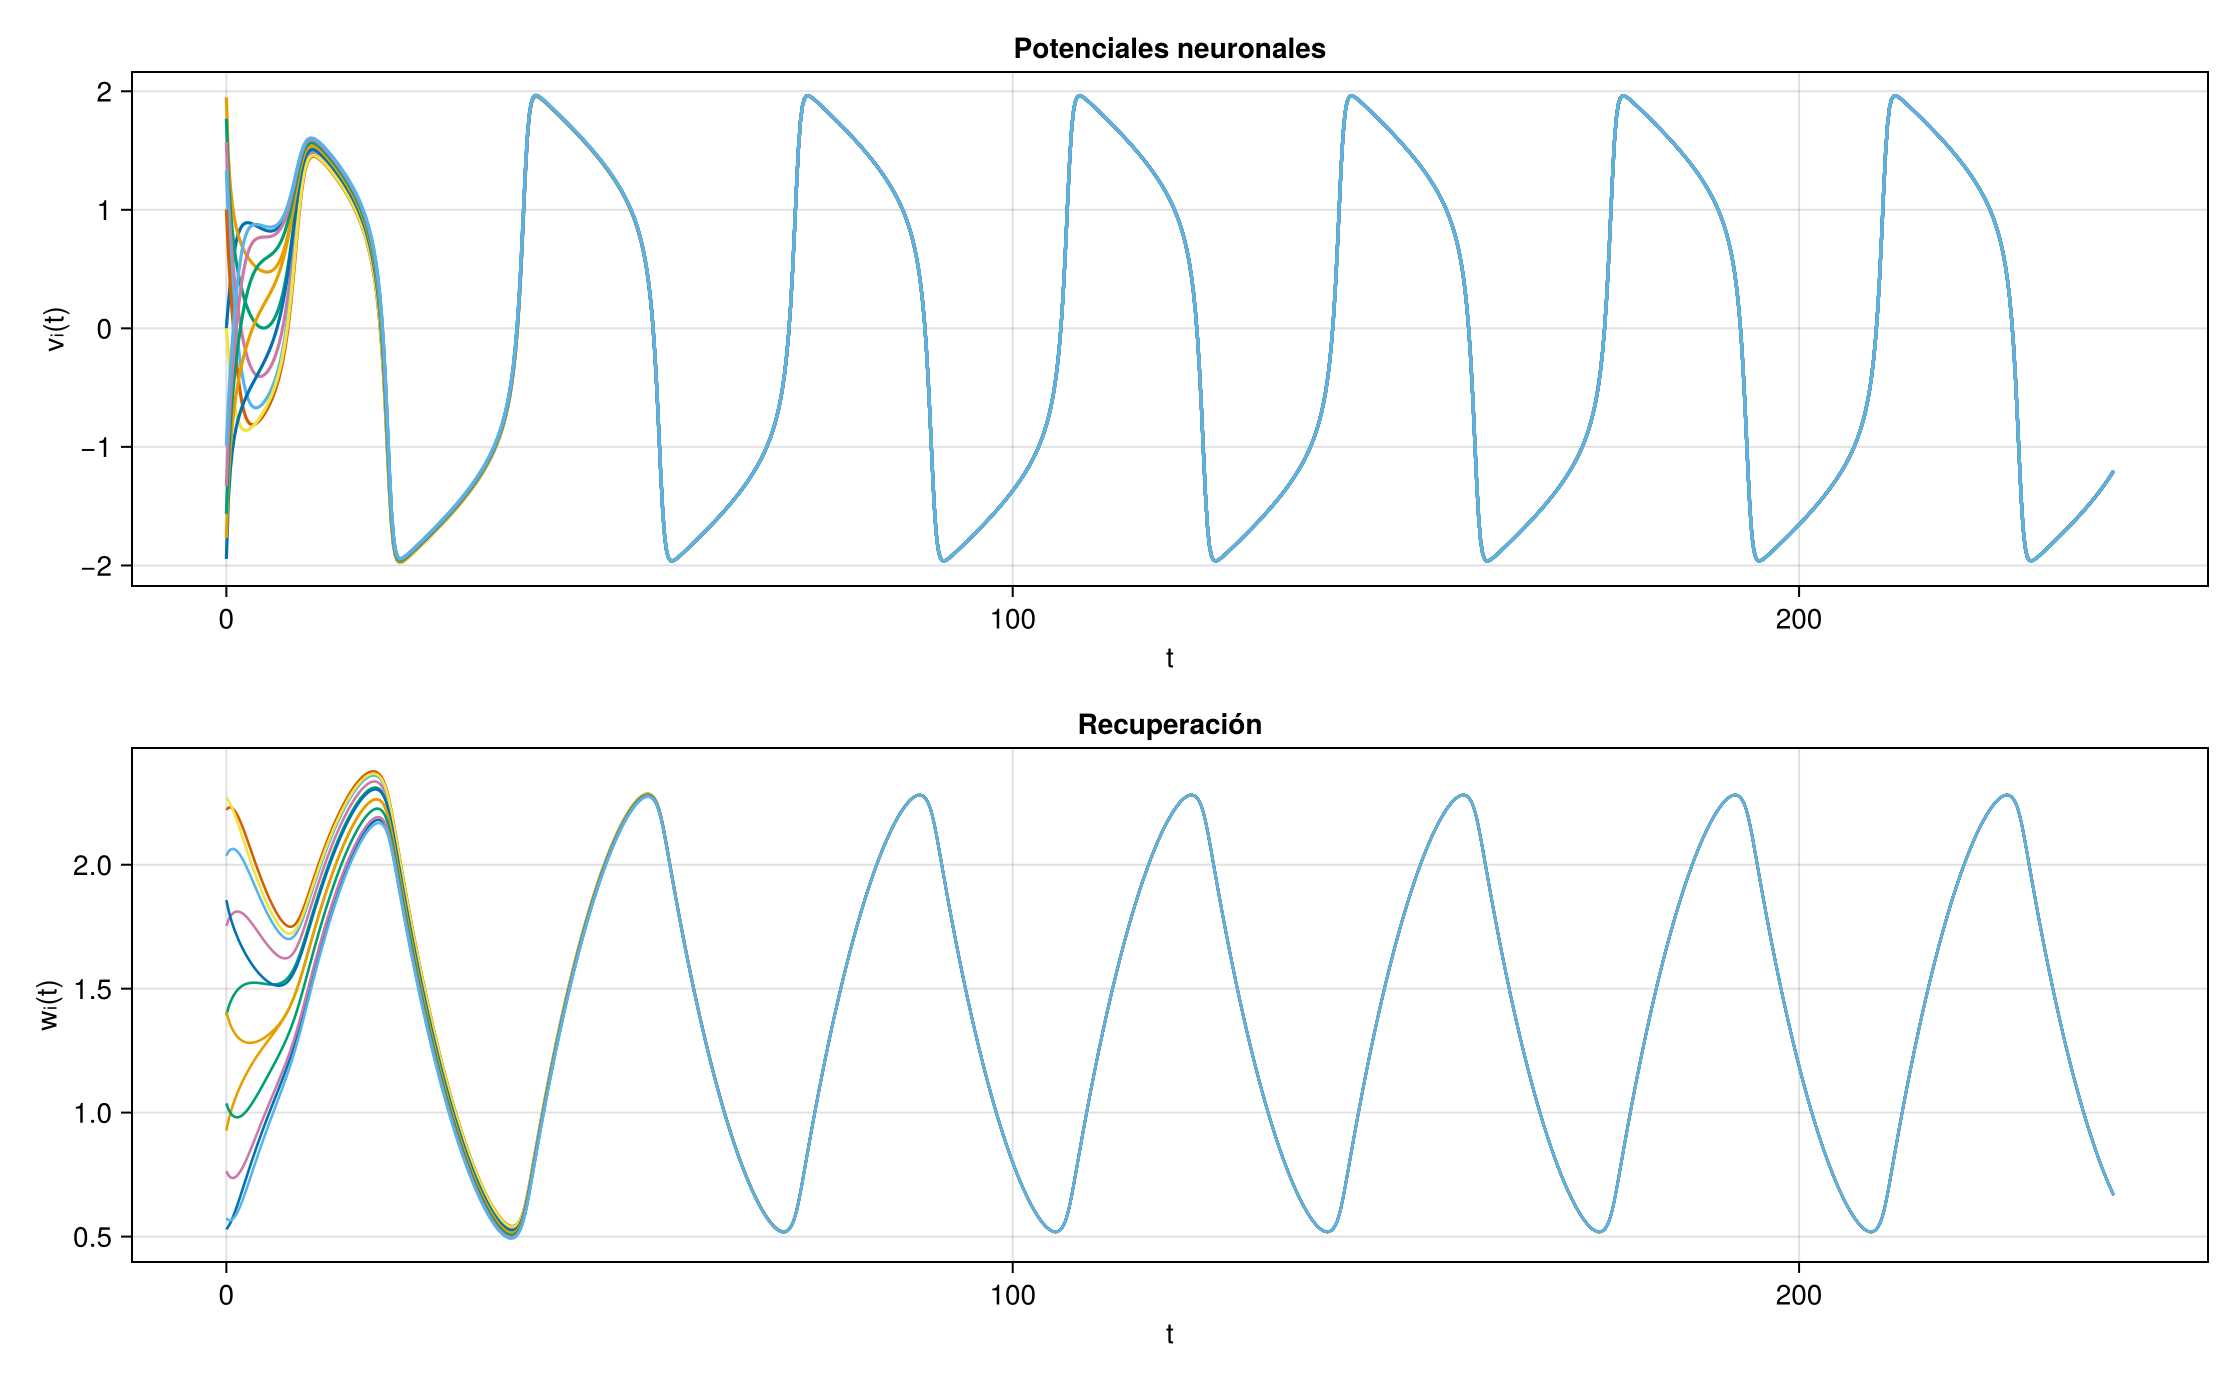

In [4]:
plot_network_timeseries(sol,net)

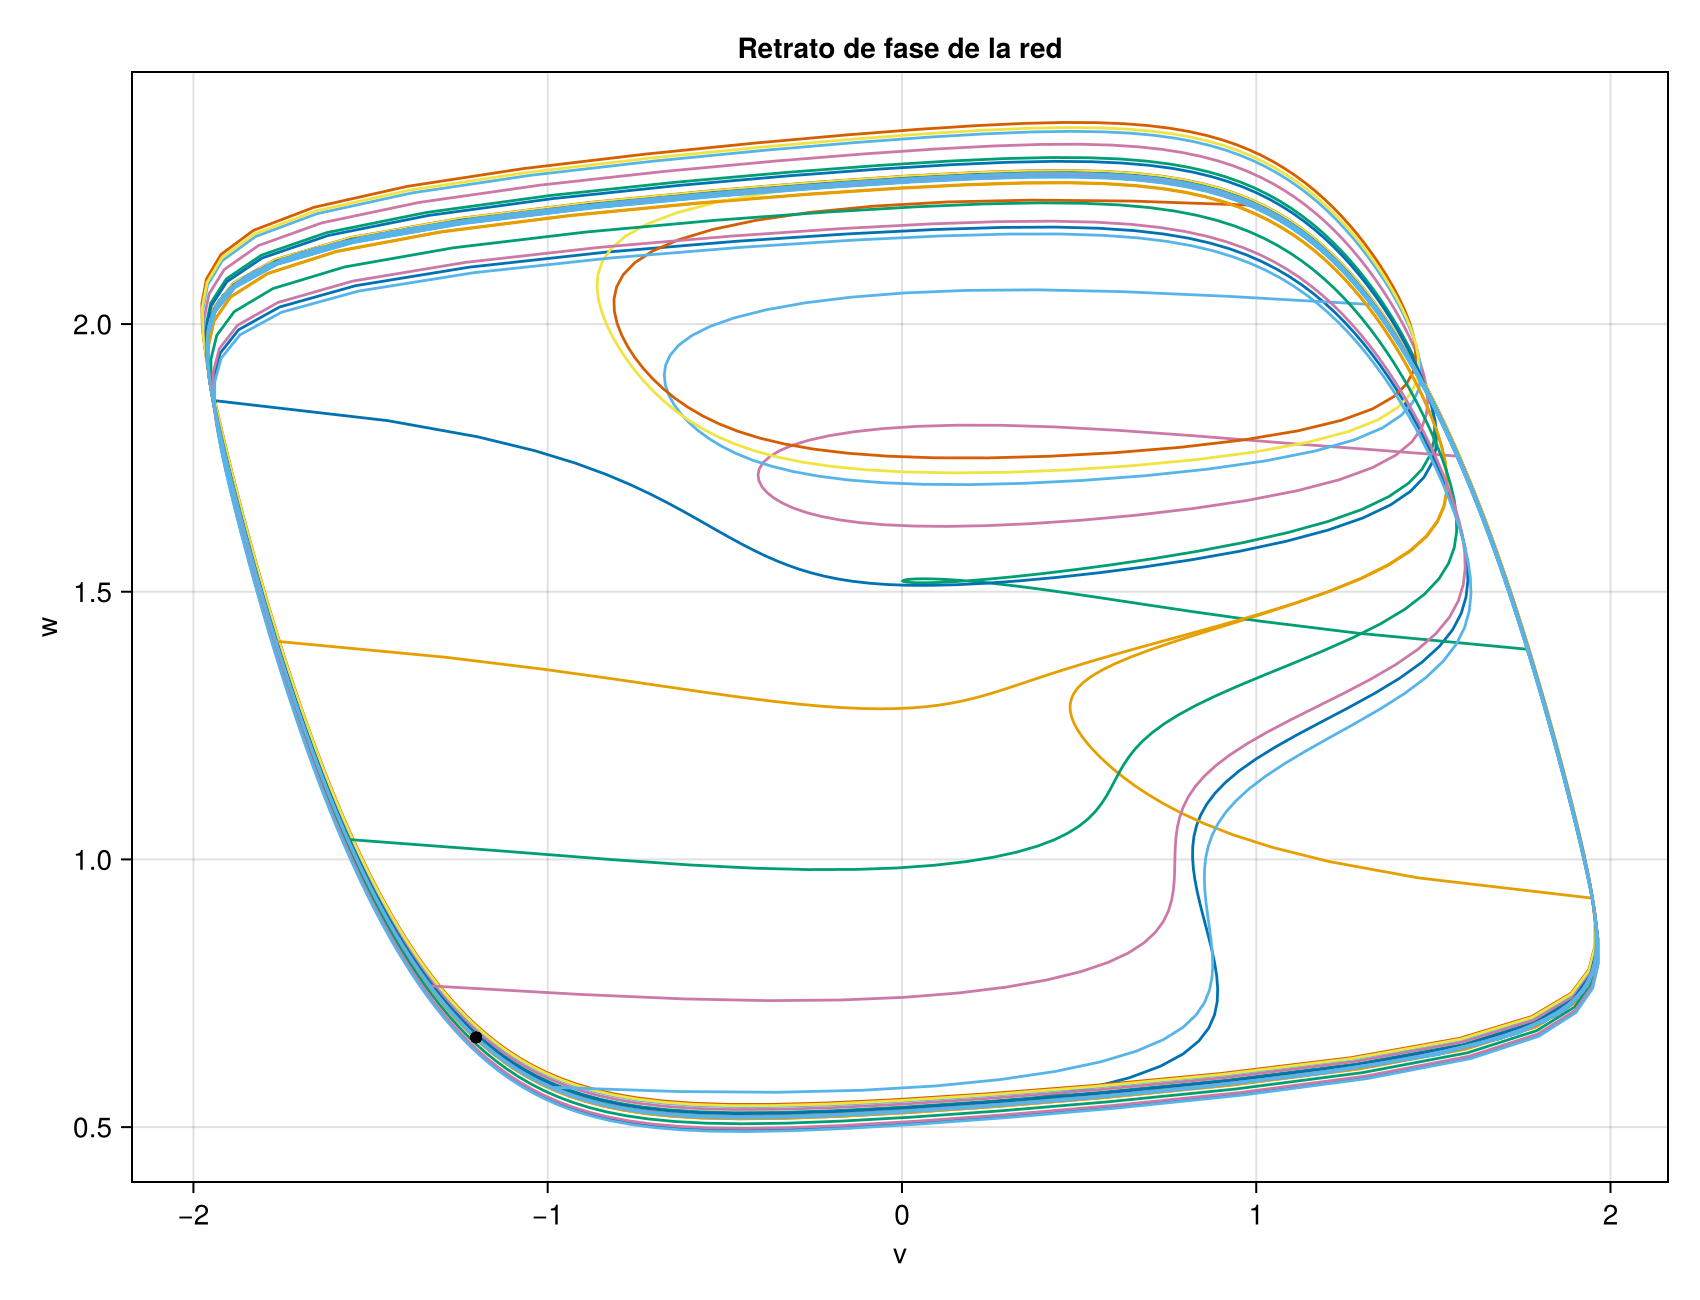

In [5]:
plot_network_phase(sol,net)

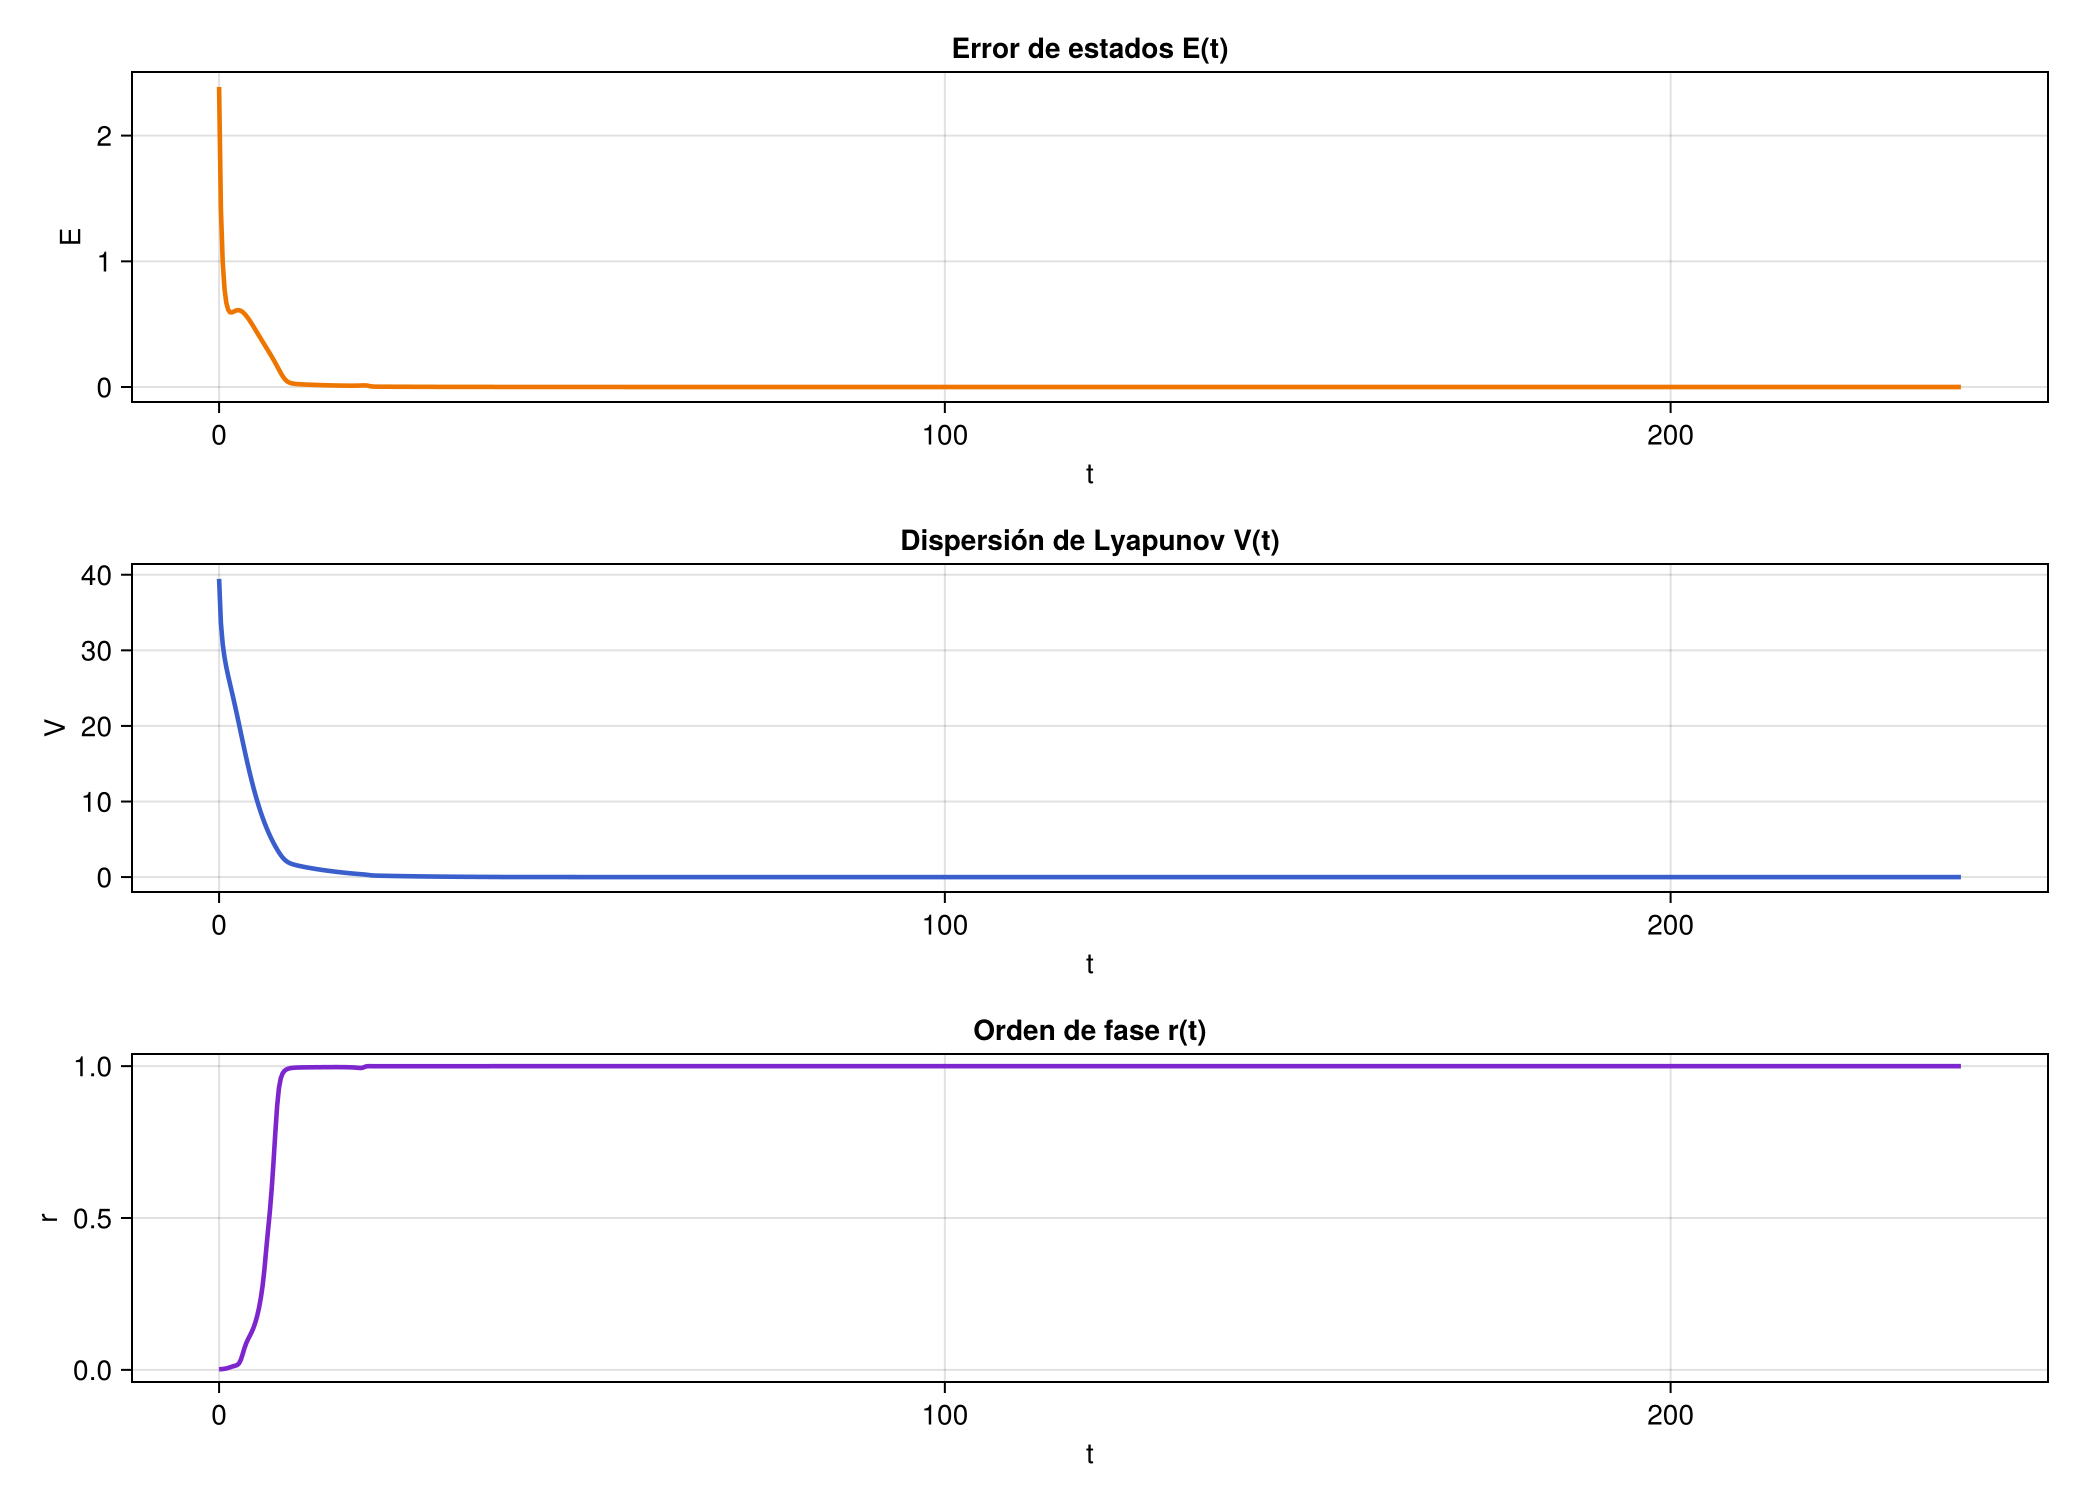

In [6]:
plot_network_metrics(metrics)

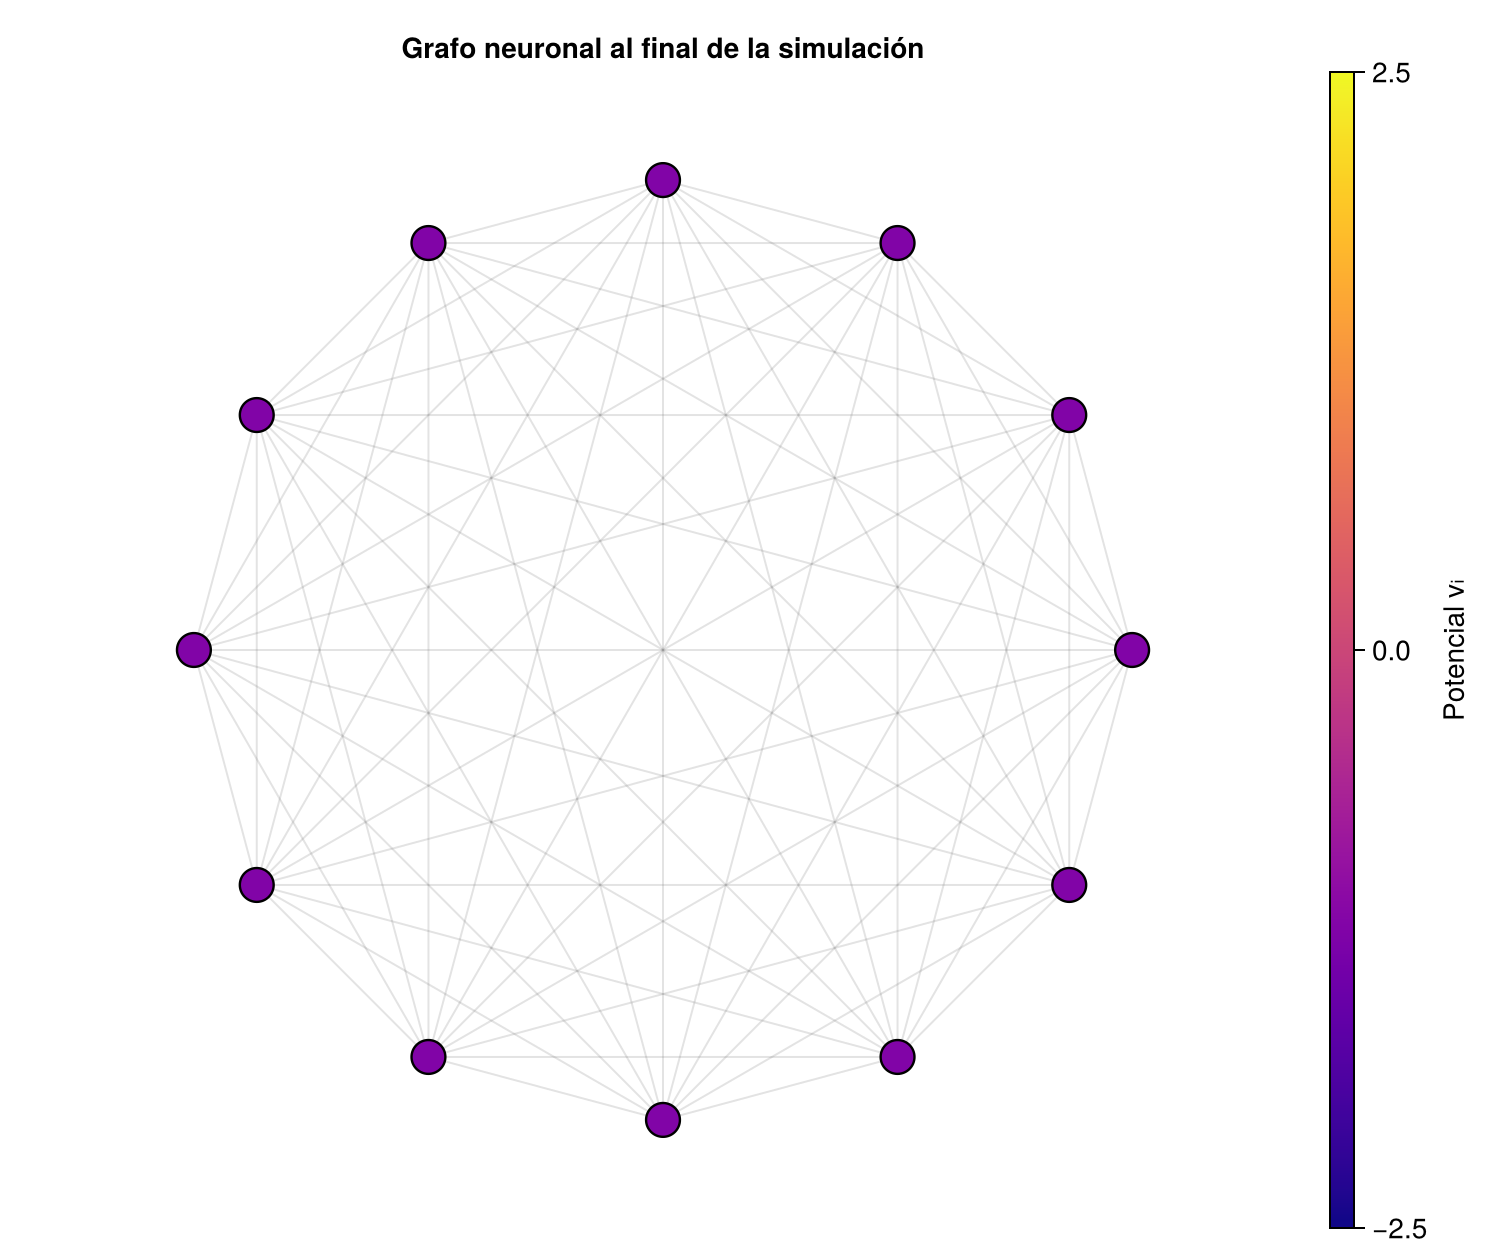

In [7]:
plot_network_snapshot(sol.u[end],net;
    title="Grafo neuronal al final de la simulación")

## 4. Comparación de intensidades de acoplamiento

Las tres simulaciones usan **el mismo estado inicial** y parámetros individuales. Los valores negativos favorecen la atracción, pero el umbral suficiente del teorema de Lyapunov **no es necesario** para observar sincronización.

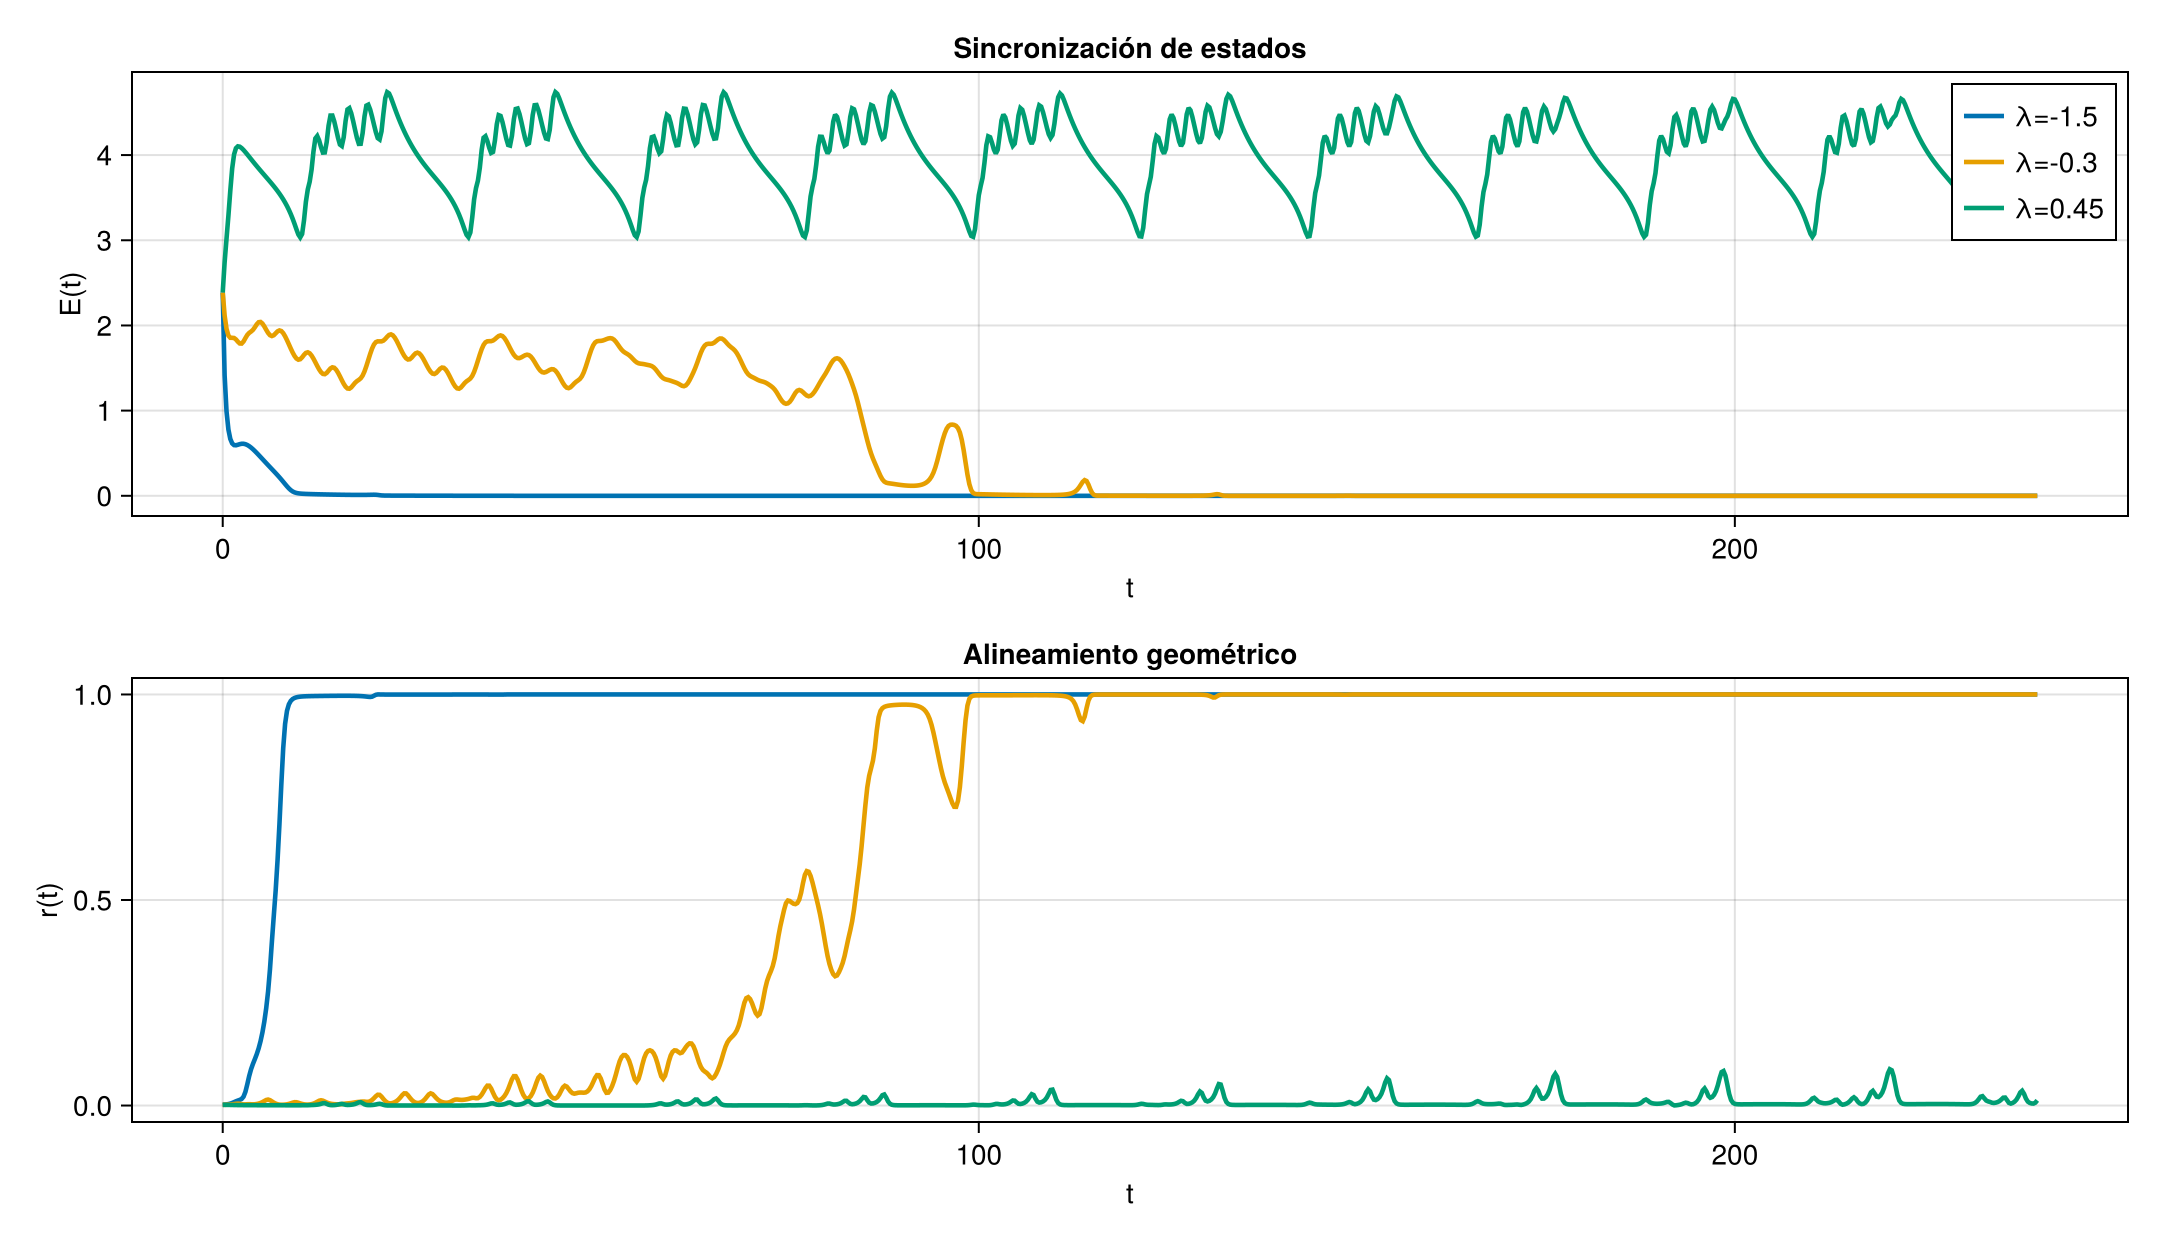

In [8]:
experiments = NamedTuple[]
for coupling in (-1.5,-0.3,0.45)
    n = FHNNetwork(N,p; adjacency=A, lambda=coupling)
    s = simulate_network(n; u0=x0, tspan=(0.,T), saveat=saveat)
    m = network_metrics(s,n; center=center)
    push!(experiments, (label="λ=$(coupling)", metrics=m))
end
plot_coupling_comparison(experiments)

## 5. Guardar y reutilizar datos

Guardamos matrices, tiempos, métricas, parámetros y tolerancias. No serializamos objetos internos del integrador ni funciones Julia, para que los resultados sean fáciles de recuperar.

In [9]:
file = joinpath(project,"data","processed","C_notebook_lambda_m1p5.jld2")
save_network_result(file,sol,net,metrics;
    description="Etapa C — notebook, lambda=$(lambda)")
data = load_network_result(file)
println("Datos guardados: ",file)
println("Dimensión de matriz de trayectoria: ",size(data["states"]))

Datos guardados: k:\Repositorios\Proyecto-COPTI\data\processed\C_notebook_lambda_m1p5.jld2
Dimensión de matriz de trayectoria: (24, 961)


## 6. Animación principal (opcional)

El grafo «parpadea»: **color = $v_i(t)$** y **tamaño = codificación visual de $v_i(t)$**, sincronizados con el plano de fase, $E(t)$ y $r(t)$. La animación no recalcula ninguna EDO. Activa `CREAR_GIF=true` para exportar un GIF que puedas insertar en un informe o notebook. Para MP4 puedes utilizar el script `scripts/run_stage_C.jl --video`.

In [10]:
CREAR_GIF = false  # Cambiar a true para producir la animación
if CREAR_GIF
    outfile = joinpath(project,"docs","videos","C_01_red_sincronizacion.gif")
    animate_network_dashboard(sol,net,metrics,outfile;
                              nframes=100,framerate=20)
    println("GIF generado: ",outfile)
end

## 7. Estabilidad transversal del ciclo común (opcional)

**Para un ciclo obtenido en B**, las ecuaciones variacionales transversales incorporan $1-v_*(t)^2+\lambda$. Dos multiplicadores de Floquet con módulo menor que uno señalan atracción transversal local. Esto no prueba sincronización global ni garantiza ciclos para cualquier parámetro.

In [11]:
CALCULAR_FLOQUET = false  # Cambiar a true si deseas repetir shooting y Floquet
if CALCULAR_FLOQUET
    detection = detect_limit_cycle(p; transient=300,window=300,dt=0.35)
    @assert detection.status == :periodic_candidate
    orbit = refine_periodic_orbit(p,detection)
    @assert orbit.status == :converged
    println("Bloques del equilibrio: ", mean_field_linear_blocks(p,lambda))
    println("Floquet transversal sobre el ciclo: ",
            transverse_floquet(orbit,p,lambda))
end

## 8. Extensiones controladas

La arquitectura admite `lambda(t)` y corrientes individuales `currents(t)` sin reescribir las ecuaciones. Ejemplo: `FHNNetwork(N,p; lambda=t->t<100 ? -1.5 : 0.2)` (con paréntesis alrededor del ternario si es necesario). Una topología en anillo con `ring_adjacency(N)` es una **extensión**: no tiene automáticamente la misma cota de Lyapunov de campo medio del PDF.

**Etapa siguiente:** en D analizaremos sistemáticamente el criterio exponencial, realimentación por corrientes diferenciadas y los regímenes de sincronización/desincronización.